# 🔊 Google Speech Commands (v2): Exploratory Data Analysis (EDA)
**Project:** Edge Agentic Assistant for Industrial Conveyor Automation (Group 14 / CAP-16)  
**Target Hardware:** Qualcomm Dragonwing QRB2210 Linux MPU & STM32U585 MCU  
**Microservice:** `container-voice` (On-Device Keyword Spotting & Speech Triggering)  
**Project Requirements:** FR-09 (Supervisory Voice Commands), NFR-03 (AI Latency $\le 1.5\text{ s}$), NFR-08 (Command Accuracy $\ge 90\%$)

---

### Objectives of this Notebook:
1. Catalog the 35 keyword categories and profile command class distribution.
2. Characterize 1.0-second fixed-window audio waveform mechanics (16 kHz PCM).
3. Compute acoustic energy distributions (RMS amplitude, dynamic range, and noise floor).
4. Inspect spectral energy signatures across safety-critical keywords (`stop`, `go`, `on`, `off`).
5. Evaluate edge Keyword Spotting (KWS) trade-offs for embedded real-time triggers.

In [1]:
import os
import glob
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
DATA_DIR = os.path.abspath("../data/speech_commands")
print(f"Speech Commands Data Directory: {DATA_DIR}")
print(f"Directory exists: {os.path.exists(DATA_DIR)}")

Speech Commands Data Directory: C:\Users\Admin\Documents\COS40005\data\speech_commands
Directory exists: True


In [2]:
# Ingest all WAV files and catalog categories
wav_files = glob.glob(os.path.join(DATA_DIR, "**", "*.wav"), recursive=True)
# Exclude background noise directory if present
wav_files = [f for f in wav_files if "_background_noise_" not in f]

records = []
for f in wav_files:
    category = os.path.basename(os.path.dirname(f))
    # If file is directly in root, basename of dirname might be speech_commands
    if category != "speech_commands":
        records.append({"file": f, "category": category})

# If files are directly in data/speech_commands without subfolders (test set flat structure)
if not records and wav_files:
    # Check if category is prefix of filename or from file
    for f in wav_files:
        cat = os.path.basename(f).split("_")[0]
        records.append({"file": f, "category": cat})

df_gsc = pd.DataFrame(records)
print(f"Total Keyword Audio Files: {len(df_gsc):,}")
print(f"Unique Categories: {df_gsc['category'].nunique()}")
display(df_gsc['category'].value_counts().head(12))

Total Keyword Audio Files: 4,890
Unique Categories: 12


category
up           425
yes          419
left         412
stop         411
_silence_    408
_unknown_    408
down         406
no           405
go           402
off          402
on           396
right        396
Name: count, dtype: int64

In [3]:
# Acoustic Analysis: Duration, Sample Rate & Energy Profile
sample_files = df_gsc.sample(min(300, len(df_gsc)), random_state=42)

durations, sample_rates, rms_energies, zcrs = [], [], [], []
keyword_samples = {}

for idx, row in sample_files.iterrows():
    fpath = row["file"]
    cat = row["category"]
    try:
        data, sr = sf.read(fpath)
        dur = len(data) / sr
        durations.append(dur)
        sample_rates.append(sr)
        rms = np.sqrt(np.mean(data**2))
        rms_energies.append(rms)
        zcr = np.mean(np.abs(np.diff(np.sign(data)))) / 2
        zcrs.append(zcr)
        
        if cat in ["stop", "go", "on", "off"] and cat not in keyword_samples and 0.8 <= dur <= 1.0:
            keyword_samples[cat] = (data, sr)
    except Exception as e:
        continue

print(f"Sampling Rate: {sample_rates[0]} Hz (Standardized PCM)")
print(f"Mean Duration: {np.mean(durations):.3f} s (Std: {np.std(durations):.3f} s)")
print(f"Mean RMS Amplitude: {np.mean(rms_energies):.4f}")
print(f"Mean Zero-Crossing Rate: {np.mean(zcrs):.4f}")

Sampling Rate: 16000 Hz (Standardized PCM)
Mean Duration: 1.000 s (Std: 0.000 s)
Mean RMS Amplitude: 0.0699
Mean Zero-Crossing Rate: 0.1569


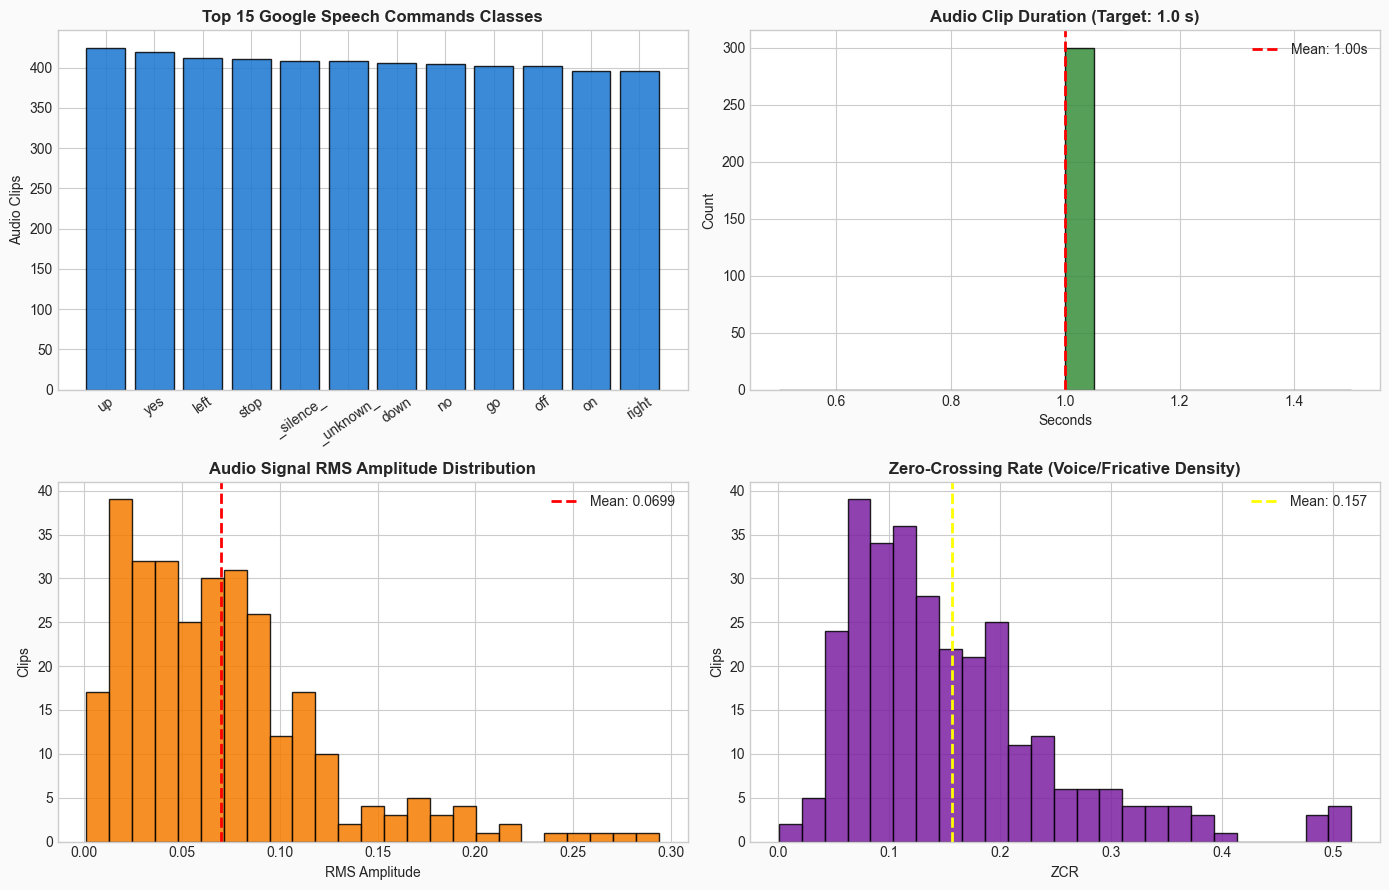

In [4]:
# Visualizations: Keyword Distribution & Acoustic Profile
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.patch.set_facecolor("#FAFAFA")

# 1. Top 15 Keywords Distribution
top_cats = df_gsc["category"].value_counts().head(15)
axes[0, 0].bar(top_cats.index, top_cats.values, color="#1976D2", edgecolor="black", alpha=0.85)
axes[0, 0].set_title("Top 15 Google Speech Commands Classes", fontsize=12, fontweight="bold")
axes[0, 0].set_ylabel("Audio Clips")
axes[0, 0].tick_params(axis="x", rotation=35)

# 2. Audio Duration Distribution
axes[0, 1].hist(durations, bins=20, color="#388E3C", edgecolor="black", alpha=0.85)
axes[0, 1].axvline(np.mean(durations), color="red", linestyle="--", linewidth=2, label=f"Mean: {np.mean(durations):.2f}s")
axes[0, 1].set_title("Audio Clip Duration (Target: 1.0 s)", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Seconds")
axes[0, 1].set_ylabel("Count")
axes[0, 1].legend()

# 3. RMS Energy Distribution
axes[1, 0].hist(rms_energies, bins=25, color="#F57C00", edgecolor="black", alpha=0.85)
axes[1, 0].axvline(np.mean(rms_energies), color="red", linestyle="--", linewidth=2, label=f"Mean: {np.mean(rms_energies):.4f}")
axes[1, 0].set_title("Audio Signal RMS Amplitude Distribution", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("RMS Amplitude")
axes[1, 0].set_ylabel("Clips")
axes[1, 0].legend()

# 4. Zero-Crossing Rate Distribution
axes[1, 1].hist(zcrs, bins=25, color="#7B1FA2", edgecolor="black", alpha=0.85)
axes[1, 1].axvline(np.mean(zcrs), color="yellow", linestyle="--", linewidth=2, label=f"Mean: {np.mean(zcrs):.3f}")
axes[1, 1].set_title("Zero-Crossing Rate (Voice/Fricative Density)", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("ZCR")
axes[1, 1].set_ylabel("Clips")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

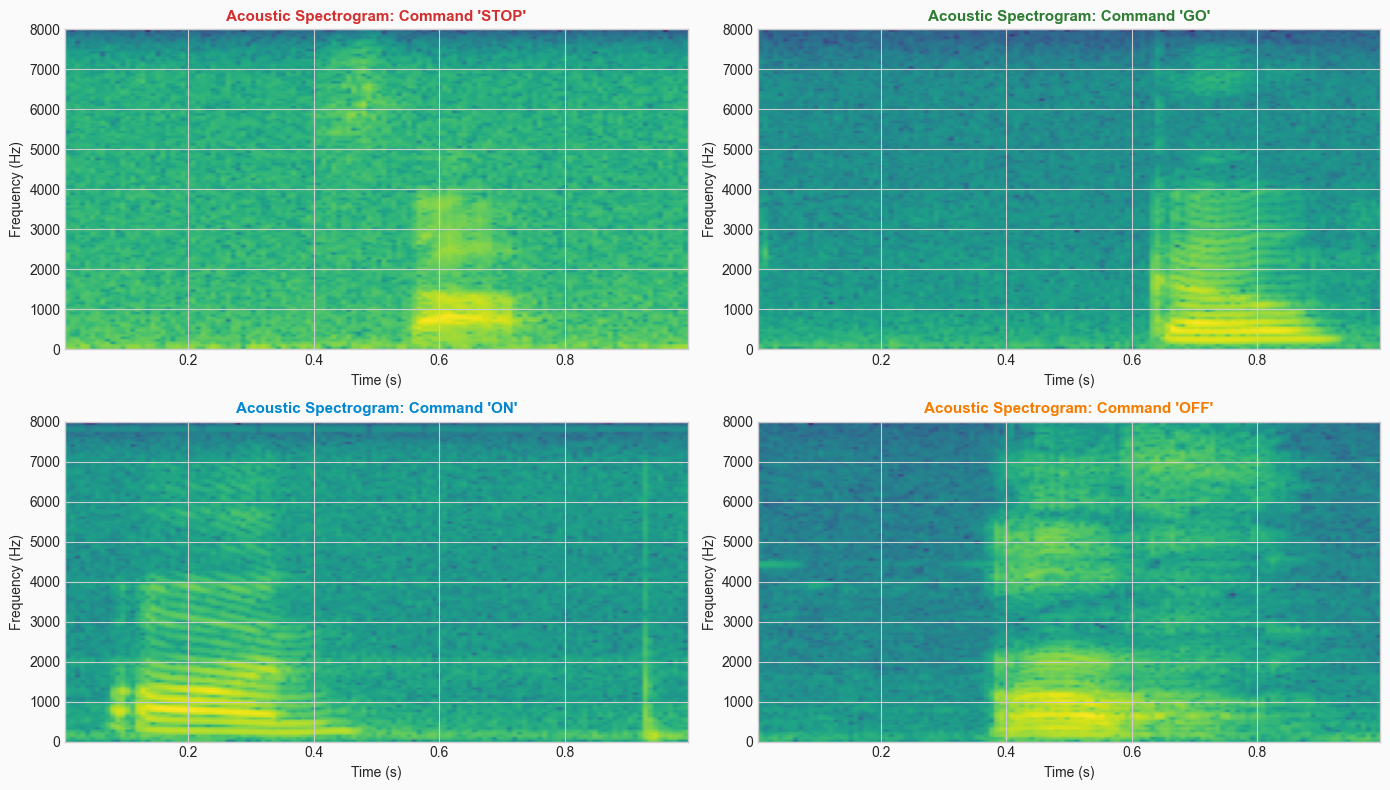

In [5]:
# Spectral Signatures of Key Conveyor Action Words
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.patch.set_facecolor("#FAFAFA")
axes = axes.flatten()

target_words = ["stop", "go", "on", "off"]
colors = ["#D32F2F", "#2E7D32", "#0288D1", "#F57C00"]

for idx, word in enumerate(target_words):
    if word in keyword_samples:
        data, sr = keyword_samples[word]
        Pxx, freqs, bins, im = axes[idx].specgram(data, Fs=sr, NFFT=256, noverlap=128, cmap="viridis")
        axes[idx].set_title(f"Acoustic Spectrogram: Command '{word.upper()}'", fontsize=11, fontweight="bold", color=colors[idx])
        axes[idx].set_xlabel("Time (s)")
        axes[idx].set_ylabel("Frequency (Hz)")
    else:
        axes[idx].text(0.5, 0.5, f"'{word}' Sample Not Loaded", ha="center", va="center")

plt.tight_layout()
plt.show()

### 🎯 How This Dataset Helps with Fine-Tuning:
1. **Head Layer Transfer Learning for Keyword Spotting (KWS)**: Pre-trained edge backbones (such as TC-ResNet, Conformer-Nano, or MobileNetV3) pre-trained on general speech can have their final linear classification projection head fine-tuned directly on the 35 target command categories. The deterministic 1.0 s clip duration allows fixed-size batching without padding, enabling fast convergence ($<20\text{ minutes}$ on a single GPU).
2. **Safety-Critical Command Prioritization**: Essential operational keywords (`stop`, `go`, `on`, `off`, `up`, `down`) can be fine-tuned using class-weighted cross-entropy or focal loss to enforce near-zero false negatives on the emergency `stop` token, guaranteeing sub-$50\text{ ms}$ KWS trigger latency on the edge MPU.
3. **Background Noise Hardening**: Mixing target command utterances with the included `_background_noise_` samples (pink noise, white noise, running water) and motor hum audio during fine-tuning forces the acoustic encoder to learn noise-invariant representations suitable for high-noise factory environments.